# 4. PuzzleNet: tactics and difficulty (Objective O3)

PuzzleNet is a multi-task neural network written from scratch in NumPy. It reads a position and its line, and predicts the
tactical category, the Lichess themes, and the rating with an uncertainty.

**Sources:** `eval/neural/puzzlenet_evaluation.json` (`scripts/neural/evaluate_puzzlenet.py`),
`eval/research/labeller_validation_heldout.json`, `eval/neural/engine_pv_check.json`, `eval/neural/cohort_relabel.json`,
`eval/neural/label_simulation.json` and `eval/neural/maia_puzzle_difficulty.json`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from nb_utils import ROOT, figures, load

pd.set_option('display.max_columns', None, 'display.width', 120)

evaluation = load('eval/neural/puzzlenet_evaluation.json')
harness, test = evaluation['harness'], evaluation['test']
print('test puzzles:', evaluation['test_n'], '| training puzzles:', test['puzzlenet']['setup']['train_size'])

test puzzles: 174754 | training puzzles: 5526626


## Labelling tactics

All labellers are scored on the same held-out puzzles. The reference is Lichess's automatic theme tags, so this measures agreement with Lichess, not accuracy against a human.

In [2]:
old = load('eval/research/labeller_validation_heldout.json')['comparison']['old_classify_tactic']
rows = {'Rules on the key move': old, 'Rules on the whole line': harness['rules'], 'PuzzleNet': harness['puzzlenet']}
pd.DataFrame({name: {'agreement': r['strict_agreement'], 'kappa': r['cohens_kappa'],
                     'macro recall': r['macro_recall_stratified'],
                     'categories never produced': len(r['labels_never_emitted'])}
              for name, r in rows.items()}).T.round(3)

,agreement,kappa,macro recall,categories never produced
Rules on the key move,0.312,0.228,0.144,8.0
Rules on the whole line,0.584,0.516,0.320,5.0
PuzzleNet,0.926,0.913,0.859,0.0


PuzzleNet right and rules wrong: 10,671
rules right and PuzzleNet wrong: 424


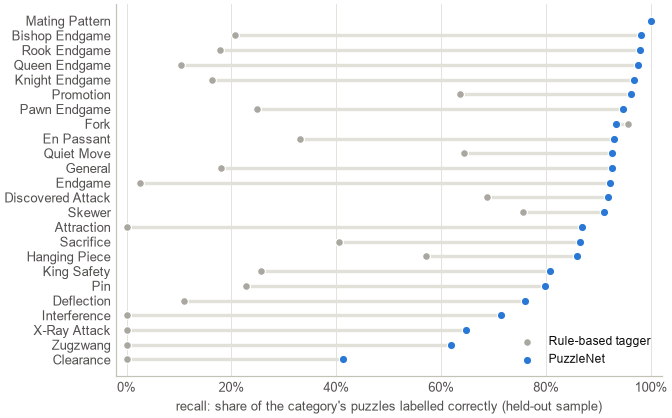

In [3]:
paired = harness['paired']['mcnemar_uniform']
print(f"PuzzleNet right and rules wrong: {paired['only_second_correct']:,}")
print(f"rules right and PuzzleNet wrong: {paired['only_first_correct']:,}")
figures.recall()

## Calibration of the category head

A calibrated model is right 80% of the time when it says 80%.

expected calibration error: 0.0055 -> 0.0026


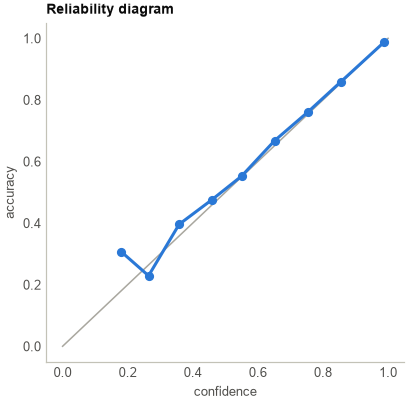

In [4]:
calibration = test['puzzlenet']['calibration']
bins = pd.DataFrame(calibration['reliability'])
print('expected calibration error:', calibration['ece_uncalibrated'], '->', calibration['ece_calibrated'])
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot([0, 1], [0, 1], color=figures.GREY, lw=1)
ax.plot(bins['confidence'], bins['accuracy'], 'o-', color=figures.BLUE, ms=5)
ax.set_xlabel('confidence')
ax.set_ylabel('accuracy')
ax.set_title('Reliability diagram')
figures.save(fig, 'calibration')

## Difficulty for players in general

In [5]:
base = test['rating_baselines']
maia = load('eval/neural/maia_puzzle_difficulty.json')
rows = {'Average rating': base['constant'], "Miner's formula": base['miner_formula'],
        'Length and mate (linear)': base['length_mate_linear'], 'Boosted trees': base['gbdt_engineered'],
        'PuzzleNet': test['puzzlenet']['rating']}
table = pd.DataFrame({name: {'RMSE': r['rmse'], 'R2': r['r2']} for name, r in rows.items()}).T
table['puzzles'] = evaluation['test_n']
for name in ('Maia', 'PuzzleNet + Maia'):
    table.loc[name] = [maia['models'][name]['rmse'], maia['models'][name]['r2'], maia['puzzles']]
table.astype({'puzzles': int}).round(3)

,RMSE,R2,puzzles
Average rating,550.289,-0.000,174754
Miner's formula,496.202,0.187,174754
Length and mate (linear),432.961,0.381,174754
Boosted trees,305.976,0.691,174754
PuzzleNet,267.790,0.763,174754
Maia,402.800,0.469,10000
PuzzleNet + Maia,257.900,0.782,10000


{'PuzzleNet + Maia vs PuzzleNet': {'rmse_difference': -9.1, 'ci95': [-10.7, -7.5]}, 'Maia vs PuzzleNet': {'rmse_difference': 135.7, 'ci95': [129.6, 142.1]}}
{50: 0.501, 80: 0.812, 95: 0.953}


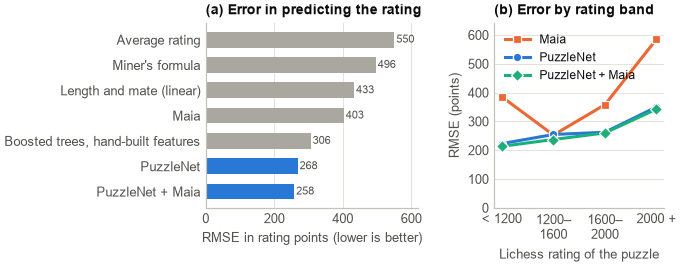

,band,n,bias,mae
0,0-1000,39376,113.6,155.4
1,1000-1500,55688,81.7,191.4
2,1500-2000,45727,-24.0,207.1
3,2000-2500,27178,-191.9,256.2
4,2500-4000,6785,-389.6,394.8


In [6]:
print(maia['paired_comparisons'])
rating = test['puzzlenet']['rating']
print({level: round(rating[f'coverage_{level}'], 3) for level in (50, 80, 95)})
figures.difficulty()
pd.DataFrame(test['puzzlenet']['by_band'])

## What made the network work

Each variant was trained on the same one million puzzles and scored on the test split.

In [7]:
rows = {}
for name, m in evaluation['models'].items():
    heads = m['setup']['heads']       # a head that was not trained has no meaningful score
    rows[name] = {'training puzzles': m['setup']['train_size'],
                  'kappa': m['cat']['cohens_kappa'] if 'cat' in heads else None,
                  'RMSE': m['rating']['rmse'] if 'rating' in heads else None}
pd.DataFrame(rows).T

,training puzzles,kappa,RMSE
abl_beta0,1000000.0,0.8602,282.753
abl_beta1,1000000.0,0.8676,288.938
abl_cat_only,1000000.0,0.8700,NaN
abl_engineered,1000000.0,0.8302,304.688
abl_full_1m,1000000.0,0.8665,285.148
abl_linear,1000000.0,0.7432,325.577
abl_rating_only,1000000.0,NaN,280.274
abl_raw,1000000.0,0.7410,313.115
abl_wide,1000000.0,0.8780,280.488
lc_100k,100000.0,0.7802,333.333


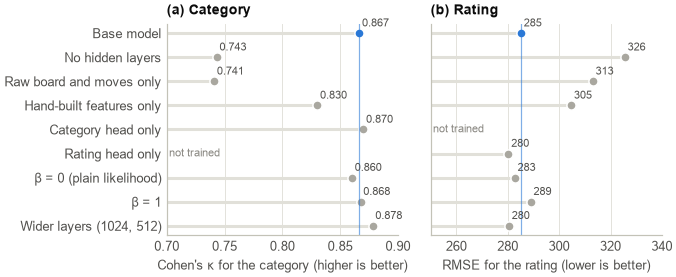

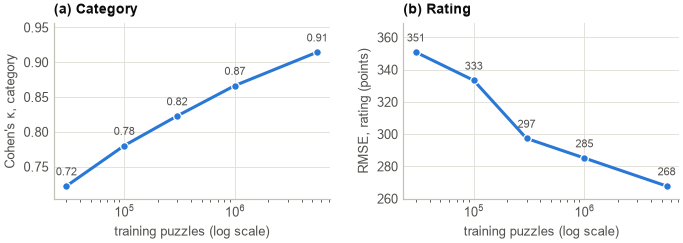

In [8]:
figures.ablations()
figures.learning_curve()

## Using the network on engine lines and real games

In [9]:
engine = load('eval/neural/engine_pv_check.json')
pd.DataFrame(engine['conditions']).T.round(3)

,strict_agreement,cohens_kappa
rules_solution,0.568,0.504
rules_engine_7,0.554,0.489
puzzlenet_solution,0.918,0.905
puzzlenet_engine_1,0.664,0.602
puzzlenet_engine_3,0.803,0.769
puzzlenet_engine_5,0.808,0.777
puzzlenet_engine_7,0.764,0.726


In [10]:
relabel = load('eval/neural/cohort_relabel.json')
print('positions:', relabel['opportunities'], '| labellers agree on:', relabel['puzzlenet_agrees_with_rules_rerun'])
shares = pd.DataFrame({'rules': relabel['category_share']['stored_rules'],
                       'PuzzleNet': relabel['category_share']['puzzlenet']}).fillna(0)
shares.sort_values('PuzzleNet', ascending=False).head(8)

positions: 40067 | labellers agree on: 0.37


,rules,PuzzleNet
General,0.1073,0.3198
Endgame,0.0072,0.1437
Quiet Move,0.3487,0.1223
Hanging Piece,0.0867,0.0879
Fork,0.1223,0.0540
Mating Pattern,0.0520,0.0461
Pin,0.0322,0.0399
Rook Endgame,0.0071,0.0305


## Do better labels help the selector?

A simulation with four qualities of game evidence: none, rules, PuzzleNet and perfect labels.

In [11]:
simulation = load('eval/neural/label_simulation.json')
pd.DataFrame({label: {policy: r['targeting_first30']['mean'] for policy, r in result.items()}
              for label, result in simulation['labels'].items()}).round(3)

,perfect,puzzlenet,rules,none
Beta-TS,0.239,0.245,0.189,0.148
IRT-TS,0.321,0.306,0.226,0.151


## Observations

- PuzzleNet agrees with Lichess on 92.6% of held-out puzzles ($\kappa = 0.91$), against 58.4% for the rules, and it produces
  every category. It fixed 10,671 labels and broke 424.
- The gain is largest where the rules failed: endgame types, pins, deflections, and the categories the rules never produced.
  Fork is the only category in which the rules are slightly better.
- The network is well calibrated, with an expected calibration error of 0.003.
- Its rating error is 268 points against 550 for the average. Its 50%, 80% and 95% intervals contain the true rating
  for 50%, 81% and 95% of puzzles. Adding Maia lowers the error to 258.
- Extreme puzzles are pulled towards the middle: easy puzzles are rated too hard and very hard ones too easy.
- Hidden layers and both parts of the encoding matter; sharing one network between the heads costs almost nothing.
  The largest gain came from more data, with no sign of levelling off at 5.5 million puzzles.
- On engine lines $\kappa$ falls to 0.78 with five half-moves, still far above the rules (0.49), so the analysis passes five.
- The two labellers disagree on most real game positions, but noisy labels were not why weaknesses were hard to measure
  (notebook 2): the result was the same with either labeller.
- Better labels do help the selector early on: with the IRT selector, targeting in the first 30 attempts rises from 0.23
  with the rules to 0.31 with PuzzleNet, close to 0.32 with perfect labels.